# Options Income Strategies under Test: Covered Calls, Cash-Secured Puts and Collars on SPY, QQQ and IWM since 2004, with Regime-Aware Machine-Learning Overlays Tested Out of Sample

Covered calls, cash-secured puts and collars are sold to investors as ways to "earn income" from an equity position or to protect it cheaply. Each changes the shape of returns: a covered call gives up the upside beyond the strike for a premium; a cash-secured put is economically the same bet as a covered call at the same strike; a collar buys downside protection with the premium from an upside cap. Whether they improve risk-adjusted returns depends on how expensive options are (the volatility risk premium), on the market's path, and on the strikes chosen. Option-income ETFs have attracted large inflows on the promise of high distributions; the question is what investors actually gave up.

This notebook reconstructs these strategies monthly on the three main U.S. index ETFs since 2004, compares them with simply holding the ETF, and asks whether a model that reads the market regime (volatility, trend, credit spreads) can choose, each month, between holding the ETF, overwriting calls and collaring, better than any fixed choice.

**What it does.**

1. It downloads daily total-return and price series of SPY, QQQ and IWM, their implied-volatility indices (VIX, VXN, RVX), the Treasury bill rate and the Baa credit spread.
2. It prices one-month options at each month-end with Black–Scholes, using at-the-money implied volatility proportional to each ETF's volatility index and a volatility skew across strikes calibrated on today's SPY option chain, and builds monthly returns of covered calls (at the money and 2% out of the money), cash-secured puts (at the money and 2% out of the money) and a collar (long a 5% out-of-the-money put, short a 3% out-of-the-money call).
3. It compares each strategy with buying and holding the ETF: return, volatility, Sharpe and Sortino ratios, maximum drawdown, upside and downside capture, and the income generated by the premiums.
4. It builds two transparent rules (overwrite only when implied volatility is above its one-year median; collar only when the ETF is below its 10-month moving average) and two machine-learning overlays (multinomial logistic regression and LightGBM) that choose each month between holding, a 2% out-of-the-money covered call and the collar. The models are trained on the three ETFs together and retrained every January from 2009 onwards.
5. It tests whether the overlays beat the best static strategy out of sample with a block bootstrap.

**Data.** SPY, QQQ and IWM adjusted and unadjusted prices and today's SPY option chain (Yahoo Finance); VIX, VXN and RVX closes, 3-month Treasury bill rate and Baa–Treasury spread (FRED).

**Methods.** Black–Scholes pricing with a calibrated volatility skew, monthly option-strategy reconstruction, performance and capture ratios, simple regime rules, walk-forward multinomial logistic regression and LightGBM, and stationary block bootstrap tests.

**Key output.** Return and risk statistics of every strategy on each ETF; the cost of the upside cap in strong markets; the choices made by the overlays; and their out-of-sample performance against the static strategies.

## 1. Option-income strategies in one page

All strategies hold one share of the ETF (or its cash equivalent) and roll one-month options at each month-end.

- **Covered call** (buy-write): own the ETF, sell a call with strike *K*. Monthly return = ETF return − max(*S*<sub>1</sub> − *K*, 0)/*S*<sub>0</sub> + call premium/*S*<sub>0</sub>. It keeps the dividends and the premium, and gives up gains above *K*.
- **Cash-secured put:** keep *K* in Treasury bills and sell a put with strike *K*. By put–call parity, a cash-secured put and a covered call at the same strike have nearly the same payoff; the differences are dividends and interest.
- **Collar:** own the ETF, buy a put 5% below and sell a call 3% above the price. The premium of the call pays for most of the put; returns are capped on both sides.

**Why returns differ from the ETF.** Selling options earns the volatility risk premium (implied volatility is on average above realised), which raises returns in flat and falling markets. But each strategy also changes the exposure: covered calls and puts sold have less upside (lower beta in rallies) and full downside beyond the premium. Over long bull markets, the capped upside usually costs more than the premium earns.

**Synthetic prices.** Historical option quotes are not freely available, so premiums are computed with Black–Scholes. At-the-money volatility is a fixed fraction κ of the ETF's 30-day volatility index (the index averages across strikes, and includes expensive out-of-the-money puts), and implied volatility rises for lower strikes and falls for higher ones according to the skew measured on today's SPY options.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import yfinance as yf
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2004
rng = np.random.default_rng(SEED)
ETFS = {"SPY": "VIXCLS", "QQQ": "VXNCLS", "IWM": "RVXCLS"}
START, OOS_START = "2004-01-01", 2009
# ATM implied vol / volatility index: makes synthetic ATM put-writing match the
# Cboe PutWrite index mean return, 1996–2026
KAPPA = 0.83
SKEW_DEFAULT = 1.2  # relative skew used if today's option chain cannot be read
CHOICES = ["Buy and hold", "Covered call 2% OTM", "Collar 5% put / 3% call"]
N_BOOT, BLOCK = 2000, 6

print(
    f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data and today's volatility skew

The skew is measured once, on today's SPY options expiring in about a month: implied volatilities of out-of-the-money puts and calls between 85% and 110% of the price are regressed on log-moneyness, and expressed relative to at-the-money volatility: σ(*K*) = σ<sub>ATM</sub> × (1 − *s* ln(*K*/*S*)). Applying today's skew to all past months is a simplification: skews were flatter before 2008 and steeper after crashes.

In [3]:
def fetch_etfs():
    for k in range(5):
        try:
            adj = yf.download(
                list(ETFS), start=START, auto_adjust=True, progress=False
            )["Close"]
            raw = yf.download(
                list(ETFS), start=START, auto_adjust=False, progress=False
            )["Close"]
            if len(adj.dropna()) > 3000:
                return pd.concat({"tr": adj, "px": raw}, axis=1)
        except Exception:
            pass
        time.sleep(10 * (k + 1))
    raise RuntimeError("Yahoo Finance download failed")


PXE = cached("etf_prices", fetch_etfs, max_age_hours=12)
PXE.index = pd.to_datetime(PXE.index)
FRD = cached(
    "fred_options_income",
    lambda: pd.DataFrame({
        k: fred.get_series(k, observation_start=START)
        for k in [*ETFS.values(), "DTB3", "BAA10Y"]
    }),
)
FRD.index = pd.to_datetime(FRD.index)


def bs(S, K, T, r, q, s, call):
    d1 = (np.log(S / K) + (r - q + 0.5 * s * s) * T) / (s * np.sqrt(T))
    d2 = d1 - s * np.sqrt(T)
    c = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return np.where(call, c, c - S * np.exp(-q * T) + K * np.exp(-r * T))


def implied(price, S, K, T, r, q, call):
    lo, hi = np.full(len(price), 1e-3), np.full(len(price), 3.0)
    for _ in range(60):
        mid = (lo + hi) / 2
        high = bs(S, K, T, r, q, mid, call) > price
        hi, lo = np.where(high, mid, hi), np.where(high, lo, mid)
    return (lo + hi) / 2


def fetch_skew():
    tk = yf.Ticker("SPY")
    for k in range(5):
        try:
            exps = pd.to_datetime(list(tk.options))
            e = exps[
                np.argmin(np.abs((exps - pd.Timestamp.today()).days - 30))
            ]
            ch = tk.option_chain(e.strftime("%Y-%m-%d"))
            spot = tk.history(period="5d")["Close"].iloc[-1]
            rows = []
            for call, d in [(True, ch.calls), (False, ch.puts)]:
                d = d[(d["bid"] > 0) & (d["ask"] > d["bid"])].copy()
                d["mid"], d["call"] = (d["bid"] + d["ask"]) / 2, call
                rows.append(d[["strike", "mid", "call"]])
            out = pd.concat(rows)
            out["spot"], out["T"] = (
                spot,
                max((e - pd.Timestamp.today().normalize()).days, 1) / 365,
            )
            return out
        except Exception:
            time.sleep(10 * (k + 1))
    raise RuntimeError("option chain unavailable")


try:
    CH = cached("spy_chain", fetch_skew, max_age_hours=24 * 7)
    spot, T0 = CH["spot"].iloc[0], CH["T"].iloc[0]
    r0 = FRD["DTB3"].dropna().iloc[-1] / 100
    otm = CH[
        ((~CH["call"]) & (CH["strike"] < spot) & (CH["strike"] > 0.85 * spot))
        | (CH["call"] & (CH["strike"] > spot) & (CH["strike"] < 1.10 * spot))
    ]
    iv = implied(
        otm["mid"].to_numpy(),
        spot,
        otm["strike"].to_numpy(),
        T0,
        r0,
        0.012,
        otm["call"].to_numpy(),
    )
    k_ = np.log(otm["strike"].to_numpy() / spot)
    b, a = np.polyfit(k_, iv, 1)
    SKEW, ATM_IV = -b / a, a
    SKEW_SRC = (
        f"today's SPY chain ({len(otm)} out-of-the-money options, expiry in"
        f" {T0 * 365:.0f} days)"
    )
except Exception as err:
    SKEW, ATM_IV, SKEW_SRC = (
        SKEW_DEFAULT,
        np.nan,
        f"default (chain unavailable: {type(err).__name__})",
    )
VIX_NOW = FRD["VIXCLS"].dropna().iloc[-1]
CAL = pd.Series({
    "κ, ATM implied vol / volatility index": KAPPA,
    "relative skew s": SKEW,
    "skew source": SKEW_SRC,
    "SPY 1-month ATM implied vol today (%)": ATM_IV * 100,
    "VIX today": VIX_NOW,
    "today's ATM IV / VIX": (
        ATM_IV * 100 / VIX_NOW if np.isfinite(ATM_IV) else np.nan
    ),
})
CAL.to_frame("value")

,value
"κ, ATM implied vol / volatility index",0.83
relative skew s,5.09
skew source,today's SPY chain (102 out-of-the-money option...
SPY 1-month ATM implied vol today (%),14.59
VIX today,20.83
today's ATM IV / VIX,0.70


## 4. Monthly strategy returns

At each month-end every option is priced with the ETF price, the bill rate, the ETF's trailing dividend yield and the skew-adjusted implied volatility, and held to the next month-end. Strategies are fully funded (no leverage); premiums are reinvested in the strategy; there are no trading costs.

In [4]:
def month_ends(s):
    s = s.dropna()
    me = s.groupby(s.index.to_period("M")).apply(lambda x: x.index[-1])
    return pd.DatetimeIndex(me.values)[:-1]


def strategies(etf):
    tr, px = PXE[("tr", etf)].dropna(), PXE[("px", etf)].dropna()
    me = month_ends(tr)
    vol = FRD[ETFS[etf]].ffill().reindex(me, method="ffill") / 100
    rf = np.log(1 + FRD["DTB3"].ffill().reindex(me, method="ffill") / 100)
    q = (
        (np.log(tr / tr.shift(252)) - np.log(px / px.shift(252)))
        .reindex(me)
        .fillna(0.015)
        .clip(0, 0.04)
    )
    S0, S1 = px.reindex(me).to_numpy()[:-1], px.reindex(me).to_numpy()[1:]
    T0, T1 = tr.reindex(me).to_numpy()[:-1], tr.reindex(me).to_numpy()[1:]
    T = np.diff(me).astype("timedelta64[D]").astype(float) / 365
    r_, q_, v = (
        rf.to_numpy()[:-1],
        q.to_numpy()[:-1],
        KAPPA * vol.to_numpy()[:-1],
    )
    sig = lambda m: v * (1 - SKEW * np.log(m))
    etf_r = T1 / T0 - 1
    cash = np.exp(r_ * T) - 1
    out = {"Buy and hold": etf_r}
    for lab, m in [("Covered call ATM", 1.00), ("Covered call 2% OTM", 1.02)]:
        c = bs(S0, m * S0, T, r_, q_, sig(m), True)
        out[lab] = (
            etf_r + (c * np.exp(r_ * T) - np.maximum(S1 - m * S0, 0)) / S0
        )
    for lab, m in [
        ("Cash-secured put ATM", 1.00),
        ("Cash-secured put 2% OTM", 0.98),
    ]:
        p = bs(S0, m * S0, T, r_, q_, sig(m), False)
        out[lab] = (
            (m * S0 + p) * np.exp(r_ * T) - np.maximum(m * S0 - S1, 0)
        ) / (m * S0) - 1
    p = bs(S0, 0.95 * S0, T, r_, q_, sig(0.95), False)
    c = bs(S0, 1.03 * S0, T, r_, q_, sig(1.03), True)
    out["Collar 5% put / 3% call"] = (
        etf_r
        + (
            (c - p) * np.exp(r_ * T)
            + np.maximum(0.95 * S0 - S1, 0)
            - np.maximum(S1 - 1.03 * S0, 0)
        )
        / S0
    )
    R_ = pd.DataFrame(out, index=me[1:])
    R_["Bills"] = cash
    prem = pd.DataFrame(
        {
            "call ATM": bs(S0, S0, T, r_, q_, sig(1.0), True) / S0,
            "call 2% OTM": bs(S0, 1.02 * S0, T, r_, q_, sig(1.02), True) / S0,
            "put ATM": bs(S0, S0, T, r_, q_, sig(1.0), False) / S0,
            "collar net premium": (c - p) / S0,
        },
        index=me[1:],
    )
    return R_, prem


RET, PREM = {}, {}
for e in ETFS:
    RET[e], PREM[e] = strategies(e)
STRATS = [c for c in RET["SPY"].columns if c != "Bills"]


def perf(x, rf, bench):
    ex = x - rf
    w_ = (1 + x).cumprod()
    up, dn = bench > 0, bench <= 0
    return pd.Series({
        "annual return (%)": (w_.iloc[-1] ** (12 / len(x)) - 1) * 100,
        "volatility (%)": x.std() * np.sqrt(12) * 100,
        "Sharpe": ex.mean() / ex.std() * np.sqrt(12),
        "Sortino": (
            ex.mean() / np.sqrt((np.minimum(ex, 0) ** 2).mean()) * np.sqrt(12)
        ),
        "max drawdown (%)": (w_ / w_.cummax() - 1).min() * 100,
        "worst month (%)": x.min() * 100,
        "upside capture": x[up].mean() / bench[up].mean(),
        "downside capture": x[dn].mean() / bench[dn].mean(),
        "beta": np.cov(x, bench)[0, 1] / bench.var(),
    })


FULL = pd.concat({
    e: (
        pd.DataFrame({
            s: perf(RET[e][s], RET[e]["Bills"], RET[e]["Buy and hold"])
            for s in STRATS
        }).T
    )
    for e in ETFS
})
INCOME = pd.concat({
    e: (
        (PREM[e].mean() * 12 * 100).rename(
            "mean annualised premium (% of price)"
        )
    )
    for e in ETFS
}).unstack()
print(
    f"{len(RET['SPY'])} months per ETF, {RET['SPY'].index[0]:%Y-%m} to"
    f" {RET['SPY'].index[-1]:%Y-%m}"
)
display(FULL.style.format("{:.2f}"))
INCOME.style.format("{:.1f}")

273 months per ETF, 2004-02 to 2026-10


,call ATM,call 2% OTM,put ATM,collar net premium
SPY,21.7,10.3,21.8,-1.3
QQQ,25.9,13.5,25.0,-1.4
IWM,28.3,15.6,27.9,-2.2


## 5. When do the strategies win?

Months are grouped by the ETF's own return over the month. The table reports, for SPY, the average monthly return of each strategy in each bucket: income strategies win in flat and modestly falling months, lose against the ETF in strong rallies, and give little protection in crashes (except the collar).

In [5]:
spy = RET["SPY"]
bk = pd.cut(
    spy["Buy and hold"],
    [-1, -0.05, -0.01, 0.01, 0.03, 1],
    labels=[
        "below −5%",
        "−5% to −1%",
        "−1% to +1%",
        "+1% to +3%",
        "above +3%",
    ],
)
BUCKETS = (spy[STRATS].groupby(bk, observed=True).mean() * 100).T
BUCKETS.loc["months"] = spy.groupby(bk, observed=True).size()
BUCKETS.style.format("{:.2f}")

Buy and hold,below −5%,−5% to −1%,−1% to +1%,+1% to +3%,above +3%
Buy and hold,-7.89,-2.52,0.10,1.96,5.36
Covered call ATM,-5.45,-0.89,1.58,1.67,2.21
Covered call 2% OTM,-6.51,-1.82,0.85,2.41,3.20
Cash-secured put ATM,-5.49,-0.89,1.54,1.68,2.23
Cash-secured put 2% OTM,-4.21,0.33,1.19,1.04,1.60
Collar 5% put / 3% call,-5.09,-2.57,0.02,1.92,2.96
months,24.00,51.00,48.00,69.00,81.00


## 6. Regime rules and machine-learning overlays

Each month the overlay chooses one of three positions for the next month: **hold** the ETF, a **2% out-of-the-money covered call**, or the **collar**. Inputs, all known at the month-end:

- the volatility index, its ratio to the ETF's realised volatility over the last month (a measure of how expensive options are), and its change over the month;
- the ETF's return over the last 1, 3 and 12 months and its distance from the 10-month moving average (trend);
- the Baa–Treasury credit spread and the bill rate.

The target is the choice that would have earned the most over the next month. A multinomial logistic regression and LightGBM are trained on the three ETFs together, every January from 2009 on all earlier months, and the position with the highest predicted probability is taken. Two simple rules serve as benchmarks: **overwrite when expensive** (covered call when the volatility index is above its trailing one-year median, otherwise hold) and **collar in downtrends** (collar when the ETF is below its 10-month moving average, otherwise hold).

In [6]:
rows = []
for e in ETFS:
    tr = PXE[("tr", e)].dropna()
    me = RET[e].index
    lr = np.log(tr).diff()
    rv = lr.rolling(21).std() * np.sqrt(252)
    vol = FRD[ETFS[e]].ffill()
    prev = me - pd.offsets.MonthEnd(1)
    f = pd.DataFrame(index=me)
    f["vol_index"] = vol.reindex(me, method="ffill").to_numpy()
    f["vol_over_realised"] = f["vol_index"] / (
        rv.reindex(me, method="ffill").to_numpy() * 100
    )
    f["vol_change_1m"] = np.log(f["vol_index"] / f["vol_index"].shift(1))
    m_tr = tr.reindex(me, method="ffill")
    f["ret_1m"], f["ret_3m"], f["ret_12m"] = (
        m_tr.pct_change(),
        m_tr.pct_change(3),
        m_tr.pct_change(12),
    )
    f["trend"] = m_tr / m_tr.rolling(10).mean() - 1
    f["baa10y"] = FRD["BAA10Y"].ffill().reindex(me, method="ffill").to_numpy()
    f["bill"] = FRD["DTB3"].ffill().reindex(me, method="ffill").to_numpy()
    f["vol_median_1y"] = f["vol_index"].rolling(12).median()
    nxt = RET[e][CHOICES].shift(-1)
    f["target"] = nxt.to_numpy().argmax(1)
    f.loc[nxt.isna().any(axis=1).to_numpy(), "target"] = np.nan
    f[[f"next {c}" for c in CHOICES]] = nxt.to_numpy()
    f["next bills"] = RET[e]["Bills"].shift(-1).to_numpy()
    f["etf"] = e
    rows.append(f)
F = pd.concat(rows).rename_axis("date").reset_index()
FEATS = [
    "vol_index",
    "vol_over_realised",
    "vol_change_1m",
    "ret_1m",
    "ret_3m",
    "ret_12m",
    "trend",
    "baa10y",
    "bill",
]
F = F.dropna(subset=FEATS)

PRED = {
    "Logistic overlay": pd.Series(np.nan, index=F.index),
    "LightGBM overlay": pd.Series(np.nan, index=F.index),
}
for year in range(OOS_START, F["date"].dt.year.max() + 1):
    trn = F[
        (F["date"].dt.year < year)
        & F["target"].notna()
        & (F["date"] < pd.Timestamp(f"{year}-01-01") - pd.offsets.MonthEnd(1))
    ]
    tst = F.index[F["date"].dt.year == year]
    y = trn["target"].astype(int)
    lr_ = make_pipeline(
        StandardScaler(), LogisticRegression(C=0.3, max_iter=3000)
    ).fit(trn[FEATS], y)
    PRED["Logistic overlay"][tst] = lr_.classes_[
        lr_.predict_proba(F.loc[tst, FEATS]).argmax(1)
    ]
    gb = lgb.train(
        dict(
            objective="multiclass",
            num_class=3,
            learning_rate=0.03,
            num_leaves=4,
            min_child_samples=20,
            verbose=-1,
            seed=SEED,
            n_jobs=2,
        ),
        lgb.Dataset(trn[FEATS], y),
        200,
    )
    PRED["LightGBM overlay"][tst] = gb.predict(F.loc[tst, FEATS]).argmax(1)
oos = F[F["date"].dt.year >= OOS_START].copy()
oos = oos.dropna(subset=[f"next {c}" for c in CHOICES])
choice = {
    "Logistic overlay": PRED["Logistic overlay"][oos.index].astype(int),
    "LightGBM overlay": PRED["LightGBM overlay"][oos.index].astype(int),
    "Overwrite when expensive": np.where(
        oos["vol_index"] > oos["vol_median_1y"], 1, 0
    ),
    "Collar in downtrends": np.where(oos["trend"] < 0, 2, 0),
}
nx = oos[[f"next {c}" for c in CHOICES]].to_numpy()
OV = {}
for e in ETFS:
    m = (oos["etf"] == e).to_numpy()
    d = {
        c: pd.Series(nx[m, i], index=oos.loc[m, "date"])
        for i, c in enumerate(CHOICES)
    }
    d["Covered call ATM"] = (
        RET[e]["Covered call ATM"]
        .shift(-1)
        .reindex(oos.loc[m, "date"])
        .set_axis(oos.loc[m, "date"])
    )
    for k, ch in choice.items():
        d[k] = pd.Series(
            nx[m][np.arange(m.sum()), np.asarray(ch)[m]],
            index=oos.loc[m, "date"],
        )
    d["bills"] = pd.Series(
        oos.loc[m, "next bills"].to_numpy(), index=oos.loc[m, "date"]
    )
    OV[e] = pd.DataFrame(d)
OVER = pd.concat({
    e: (
        pd.DataFrame({
            s: perf(OV[e][s], OV[e]["bills"], OV[e]["Buy and hold"])
            for s in OV[e].columns
            if s != "bills"
        }).T
    )
    for e in ETFS
})
CHOICE_MIX = pd.DataFrame({
    k: (
        pd.Series(np.asarray(v))
        .map(dict(enumerate(CHOICES)))
        .value_counts(normalize=True)
    )
    for k, v in choice.items()
}).T.fillna(0)
ACC = pd.Series({
    k: np.mean(np.asarray(v) == oos["target"].astype(int).to_numpy())
    for k, v in choice.items()
})
ACC["always the most frequent past winner"] = np.mean(
    oos["target"].astype(int).to_numpy()
    == F.loc[F["date"].dt.year < OOS_START, "target"].mode()[0]
)
display(OVER.style.format("{:.2f}"))
display(CHOICE_MIX.style.format("{:.0%}"))
ACC.to_frame("share of months choosing the ex-post best").style.format(
    "{:.1%}"
)

,Buy and hold,Collar 5% put / 3% call,Covered call 2% OTM
Logistic overlay,18%,5%,77%
LightGBM overlay,23%,2%,75%
Overwrite when expensive,56%,0%,44%
Collar in downtrends,80%,20%,0%


,share of months choosing the ex-post best
Logistic overlay,49.5%
LightGBM overlay,48.7%
Overwrite when expensive,38.3%
Collar in downtrends,29.0%
always the most frequent past winner,54.8%


In [7]:
def stationary_bootstrap_idx(n, block, rng_):
    idx = np.empty(n, dtype=int)
    idx[0] = rng_.integers(n)
    for i in range(1, n):
        idx[i] = (
            rng_.integers(n)
            if rng_.random() < 1 / block
            else (idx[i - 1] + 1) % n
        )
    return idx


boot_rng = np.random.default_rng(SEED)
# the three ETFs pooled, equally weighted each month
pool = pd.concat([OV[e].assign(etf=e) for e in ETFS])
port = pool.groupby(level=0).mean(numeric_only=True)
sh = lambda x, b: (x - b).mean() / (x - b).std() * np.sqrt(12)
IDX = [
    stationary_bootstrap_idx(len(port), BLOCK, boot_rng) for _ in range(N_BOOT)
]
best_static = max(
    CHOICES + ["Covered call ATM"], key=lambda c: sh(port[c], port["bills"])
)
BOOT = {}
for k in [
    "Logistic overlay",
    "LightGBM overlay",
    "Overwrite when expensive",
    "Collar in downtrends",
]:
    x, b0, rf_ = (
        port[k].to_numpy(),
        port[best_static].to_numpy(),
        port["bills"].to_numpy(),
    )
    diffs = np.array([
        sh(pd.Series(x[i]), pd.Series(rf_[i]))
        - sh(pd.Series(b0[i]), pd.Series(rf_[i]))
        for i in IDX
    ])
    BOOT[k] = {
        "Sharpe (equal-weight ETFs)": sh(port[k], port["bills"]),
        f"Sharpe of {best_static}": sh(port[best_static], port["bills"]),
        "difference": (
            sh(port[k], port["bills"]) - sh(port[best_static], port["bills"])
        ),
        "bootstrap p-value (one-sided)": (diffs <= 0).mean(),
    }
BOOT = pd.DataFrame(BOOT).T
BOOT.style.format(
    {c: "{:.2f}" for c in BOOT.columns if "p-value" not in c}
    | {"bootstrap p-value (one-sided)": "{:.3f}"}
)

,Sharpe (equal-weight ETFs),Sharpe of Buy and hold,difference,bootstrap p-value (one-sided)
Logistic overlay,0.74,0.91,-0.17,0.988
LightGBM overlay,0.77,0.91,-0.15,0.944
Overwrite when expensive,0.80,0.91,-0.12,0.966
Collar in downtrends,0.76,0.91,-0.16,0.985


## 7. Charts and dashboard

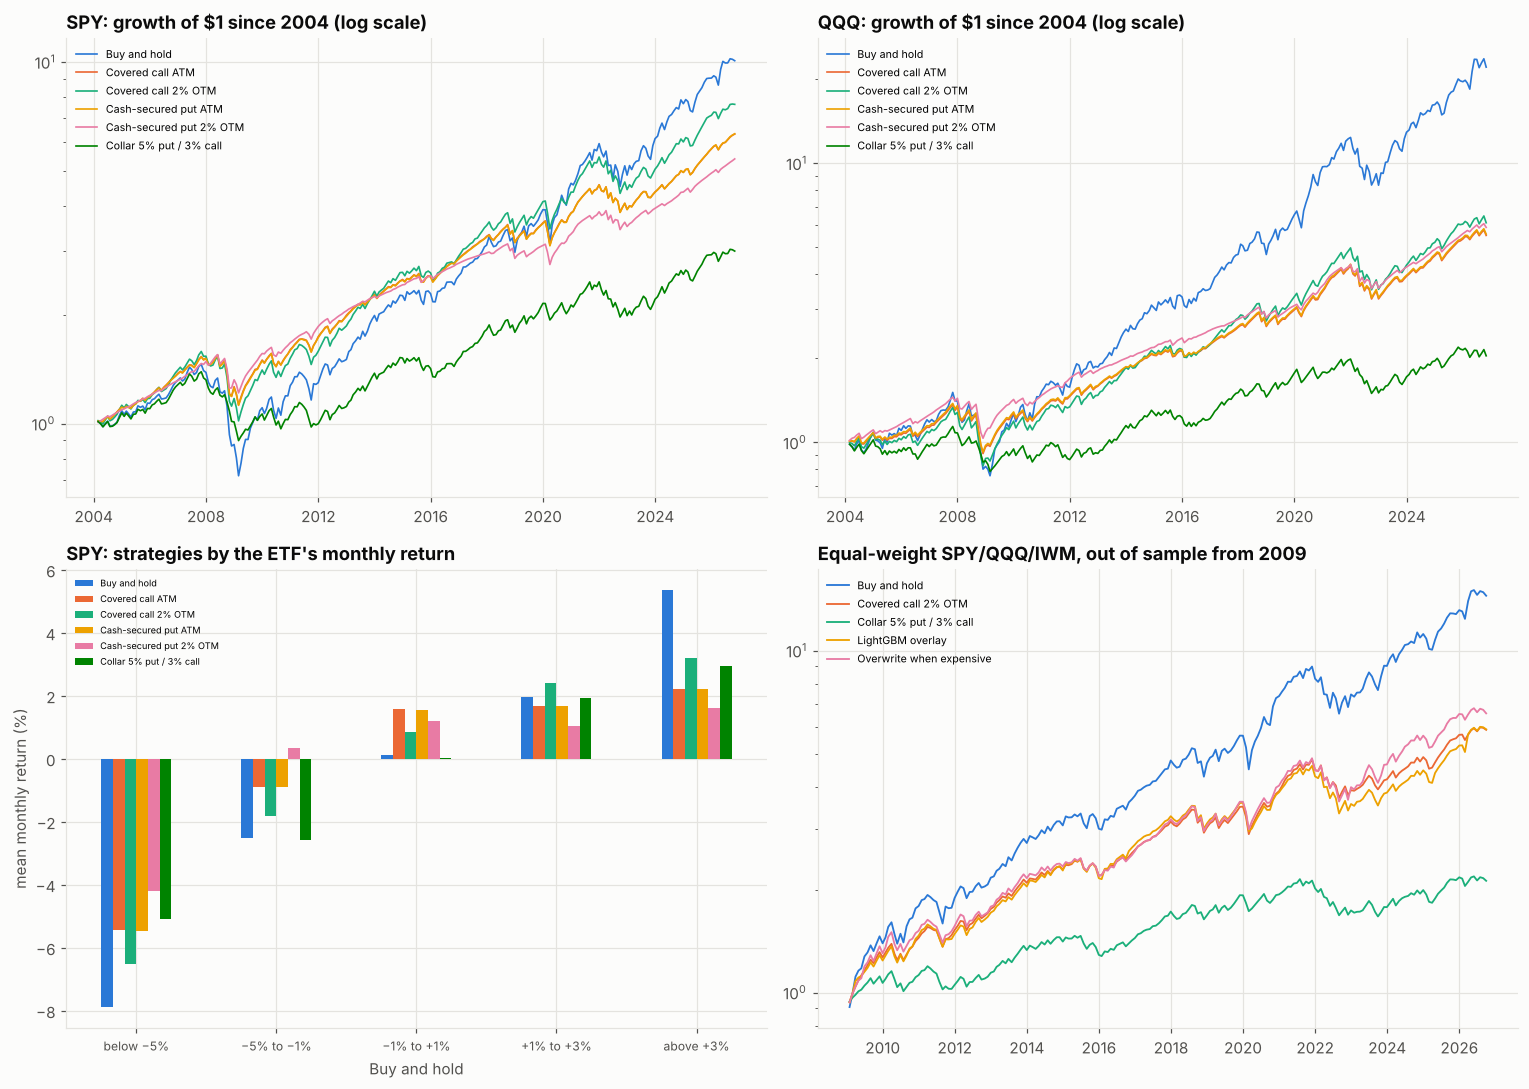

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for j, e in enumerate(["SPY", "QQQ"]):
    a = ax[0, j]
    for i, s in enumerate(STRATS):
        a.plot(
            RET[e].index,
            (1 + RET[e][s]).cumprod(),
            color=PALETTE[i % len(PALETTE)],
            lw=1.1,
            label=s,
        )
    a.set_yscale("log")
    a.set_title(f"{e}: growth of $1 since 2004 (log scale)")
    a.legend(fontsize=7)
a = ax[1, 0]
BUCKETS.drop(index="months").T.plot.bar(ax=a, color=PALETTE[: len(STRATS)])
a.set_ylabel("mean monthly return (%)")
a.set_title("SPY: strategies by the ETF's monthly return")
a.legend(fontsize=6)
a.tick_params(axis="x", rotation=0, labelsize=8)
a = ax[1, 1]
for i, k in enumerate([
    "Buy and hold",
    "Covered call 2% OTM",
    "Collar 5% put / 3% call",
    "LightGBM overlay",
    "Overwrite when expensive",
]):
    a.plot(
        port.index, (1 + port[k]).cumprod(), color=PALETTE[i], lw=1.2, label=k
    )
a.set_yscale("log")
a.set_title("Equal-weight SPY/QQQ/IWM, out of sample from 2009")
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_options_income")
plt.show()

In [9]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Sharpe ratio by strategy and ETF (2004–)",
        "Upside vs downside capture (SPY)",
    ),
)
for i, e in enumerate(ETFS):
    dash.add_trace(
        go.Bar(
            x=STRATS, y=FULL.loc[e, "Sharpe"], name=e, marker_color=PALETTE[i]
        ),
        1,
        1,
    )
sp = FULL.loc["SPY"]
dash.add_trace(
    go.Scatter(
        x=sp["downside capture"],
        y=sp["upside capture"],
        mode="markers+text",
        text=sp.index,
        textposition="top center",
        marker=dict(size=10, color=PALETTE[3]),
        name="SPY strategies",
    ),
    1,
    2,
)
dash.update_layout(
    height=600,
    width=1400,
    template="simple_white",
    barmode="group",
    title="Options income strategies on SPY, QQQ and IWM",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

*Option premiums are reconstructed with Black–Scholes, not observed. Returns exclude trading costs and taxes, which would lower every option strategy further.*

**Calibration.**
- **Skew:** today's SPY options show a steep skew. A put 5% out of the money trades at about 1.26 times at-the-money volatility, and a call 3% out of the money at about 0.85 times (relative skew *s* = 5.1).
- **ATM volatility:** at-the-money one-month volatility is 14.6% against a VIX of 20.8, a ratio of 0.70, lower than the long-run 0.83 used for history.
- **Premiums collected:** selling one-month at-the-money calls every month would have collected 22% of the price a year on SPY, 26% on QQQ and 28% on IWM. Selling 2% out of the money halves that, and the collar costs about 1.3–2.2% a year net, because the puts are dearer than the calls.

**Premium income is not return.** February 2004 to October 2026 (273 months):

| SPY | Annual return | Volatility | Sharpe | Max drawdown | Upside capture | Downside capture |
|---|---|---|---|---|---|---|
| Buy and hold | 10.7% | 14.5% | 0.66 | −50.8% | 1.00 | 1.00 |
| Covered call, at the money | 8.4% | 8.4% | 0.80 | −27.2% | 0.60 | 0.47 |
| Covered call, 2% out of the money | 9.3% | 10.6% | 0.74 | −35.7% | 0.79 | 0.75 |
| Cash-secured put, at the money | 8.5% | 8.4% | 0.80 | −27.4% | 0.60 | 0.47 |
| Cash-secured put, 2% out of the money | 7.7% | 6.5% | 0.91 | −21.6% | 0.40 | 0.19 |
| Collar (5% put, 3% call) | 4.9% | 9.3% | 0.38 | −35.5% | 0.66 | 0.81 |

- **Covered calls and puts:** they cut volatility roughly in half and earned a higher Sharpe ratio on SPY and IWM, as the volatility risk premium predicts. But they gave up 1.4–3 points of annual return, and on QQQ (14.6% a year buy and hold) they gave up almost half the return (7.8% for the at-the-money covered call) with a *lower* Sharpe ratio (0.64 against 0.74).
- **Put–call parity:** a covered call and a cash-secured put at the same strike are the same trade. Their returns differ by less than 0.1 point a year.
- **The 2% out-of-the-money put:** it had the best Sharpe ratio on every ETF (0.91, 0.82 and 0.65), largely because it is a smaller equity position (beta 0.33–0.39), not because it is a better one.
- **Collar:** it was the worst strategy on every ETF (Sharpe 0.38, 0.19 and −0.10). With today's steep skew the protection costs more than the cap earns, and it still lost 35% at its worst because a 5% floor resets every month.

**The trade-off by market month (SPY):**
- **Strong rallies:** in months the ETF rose more than 3% (81 months), it gained 5.4% on average; the at-the-money covered call gained 2.2%.
- **Sharp falls:** in months it fell more than 5% (24 months), the ETF lost 7.9%, the covered call 5.5%, the out-of-the-money put 4.2% and the collar 5.1%.
- **In between:** the income strategies win in flat and mildly negative months. Strong months are frequent in a long bull market, and that is where the premium was given back.

**Regime-aware overlays, out of sample from 2009.**
- **Choices:** each month the overlays chose between holding the ETF, a 2% out-of-the-money covered call and the collar. The machine-learning models chose the covered call in 75–77% of months and the collar in 2–5%.
- **Hit rate:** they picked the month's actual best choice 49% of the time, less than simply always choosing the most frequent past winner (55%).

| Equal-weight SPY, QQQ, IWM (2009–2026) | Sharpe | Difference from buy and hold | Bootstrap p-value |
|---|---|---|---|
| Buy and hold (best static choice) | 0.91 | — | — |
| LightGBM overlay | 0.77 | −0.15 | 0.94 |
| Logistic overlay | 0.74 | −0.17 | 0.99 |
| Overwrite when volatility is expensive | 0.80 | −0.12 | 0.97 |
| Collar in downtrends | 0.76 | −0.16 | 0.99 |

- **No overlay beat holding the ETFs.** In the strong post-2009 bull market, every month spent overwriting or collaring gave up upside that regime signals could not anticipate. On SPY alone the LightGBM overlay matched buy and hold's Sharpe ratio (0.96 against 0.95) with lower volatility, but it earned 3 points a year less.
- **Simple rules:** the trend-based collar and the volatility-based overwrite did no better than the models. Both reduced drawdowns little, because the worst months often began in calm, rising markets.

**What this means for option-income products.**
- **Premiums are not yield:** the "income" is paid for with forgone upside. What matters is total return and risk, and on strongly trending assets like QQQ the cost of the cap exceeded the premium.
- **What overwriting is:** a lower-beta equity position with a modest volatility risk premium on top. A Sharpe-ratio gain is real on broad indices, but most of the risk reduction can be had more cheaply by simply holding less equity.
- **Collars:** with today's skew, collars are an expensive way to buy protection that resets every month.
- **Timing:** regime-timing of option overlays with standard signals adds no value out of sample. Any such overlay should be tested against buy and hold and against always choosing the historically best option, with bootstrap p-values.

**Limitations.**
- **Synthetic option prices:** today's skew and a fixed ratio of at-the-money volatility to the VIX are applied to all history, with month-end rolls, no bid–ask spreads, no early exercise and no taxes. Real option-income funds roll on fixed dates, often sell weekly or daily options, and pay fees.
- **Sample:** 2004–2026 is dominated by a long bull market in U.S. large caps (especially QQQ), which flatters buy and hold against capped strategies; in a flat decade the comparison would differ.

In [10]:
CAL.to_csv(OUT_DIR / "calibration.csv")
FULL.to_csv(OUT_DIR / "strategy_performance.csv")
INCOME.to_csv(OUT_DIR / "premium_income.csv")
BUCKETS.to_csv(OUT_DIR / "spy_by_market_month.csv")
OVER.to_csv(OUT_DIR / "overlays_out_of_sample.csv")
CHOICE_MIX.to_csv(OUT_DIR / "overlay_choices.csv")
ACC.to_csv(OUT_DIR / "overlay_hit_rate.csv")
BOOT.to_csv(OUT_DIR / "overlay_bootstrap.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_options_income.png, calibration.csv, dashboard.html, dashboard.png, overlay_bootstrap.csv, overlay_choices.csv, overlay_hit_rate.csv, overlays_out_of_sample.csv, premium_income.csv, spy_by_market_month.csv, strategy_performance.csv


## References

- Black, F., & Scholes, M. (1973). The pricing of options and corporate liabilities. *Journal of Political Economy*, 81(3), 637–654. https://doi.org/10.1086/260062
- Faber, M. T. (2007). A quantitative approach to tactical asset allocation. *Journal of Wealth Management*, 9(4), 69–79. https://doi.org/10.3905/jwm.2007.674809
- Hill, J. M., Balasubramanian, V., Gregory, K., & Tierens, I. (2006). Finding alpha via covered index writing. *Financial Analysts Journal*, 62(5), 29–46. https://doi.org/10.2469/faj.v62.n5.4281
- Israelov, R., & Klein, M. (2016). Risk and return of equity index collar strategies. *Journal of Alternative Investments*, 19(1), 41–54. https://doi.org/10.3905/jai.2016.19.1.041
- Israelov, R., & Nielsen, L. N. (2015). Covered calls uncovered. *Financial Analysts Journal*, 71(6), 44–57. https://doi.org/10.2469/faj.v71.n6.1
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. In *Advances in Neural Information Processing Systems 30* (pp. 3146–3154).
- Politis, D. N., & Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association*, 89(428), 1303–1313. https://doi.org/10.1080/01621459.1994.10476870
- Whaley, R. E. (2002). Return and risk of CBOE Buy Write Monthly Index. *Journal of Derivatives*, 10(2), 35–42. https://doi.org/10.3905/jod.2002.319194